# Customer Churn — Exploratory Data Analysis

**Question:** which customers leave, and what characteristics are *associated* with leaving?

Data: IBM Telco Customer Churn sample (a fictional telco, 7,043 customers, one row per customer).
This notebook reuses the project's own cleaning code (`src/`), so the data analysed here is exactly
what the model is trained on. Modelling itself lives in `python -m src.train`; its results are
summarised at the end.

> Everything below is descriptive. Churn rates by group show association, not cause.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config
from src.data_loader import download_dataset, load_raw
from src.features import add_features
from src.preprocessing import CleaningReport, clean_raw

sns.set_theme(style="whitegrid", palette="deep")
FIG = config.FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=120)

## 1. Load and check data quality

In [2]:
download_dataset()
raw = load_raw()
print(raw.shape)
raw.head()

Dataset already present: C:\Users\Admin\Downloads\portfolio-brain-and-prompts\customer-churn-prediction\data\raw\Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


In [3]:
# Every column is read as text first. Which ones have blank strings?
blank = (raw.apply(lambda s: s.str.strip()) == "").sum()
blank[blank > 0]

TotalCharges    11
dtype: int64

In [4]:
# The blank TotalCharges rows: what is their tenure?
raw.loc[raw["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20,,No
5218,2923-ARZLG,0,19.7,,No
6670,4075-WKNIU,0,73.35,,No


All blank `TotalCharges` belong to customers with **tenure 0**: they joined but have not been
billed yet. Filling them with 0.0 reflects that, which a median fill would not. No rows are dropped.

In [5]:
report = CleaningReport()
df = add_features(clean_raw(raw, report))
print("\n".join(report.steps))
df.dtypes.value_counts()

Loaded 7,043 rows, 21 columns.
Duplicate customerIDs: 0.
Rows identical to an earlier row on every column except customerID: 22. Kept: they have distinct customer IDs, so they are separate customers.
TotalCharges blank in 11 rows, all with tenure 0 (not yet billed): set to 0.0.
SeniorCitizen 0/1 mapped to No/Yes to match the other binary columns.
Target Churn mapped Yes -> 1, No -> 0.
Dropped customerID (identifier, not a feature).
Result: 7,043 rows, 19 features + target.


str        16
float64     5
int64       1
object      1
Name: count, dtype: int64

## 2. Target: how many customers churn?

Churn
Stayed     5174
Churned    1869
Name: count, dtype: int64 
churn rate = 0.265


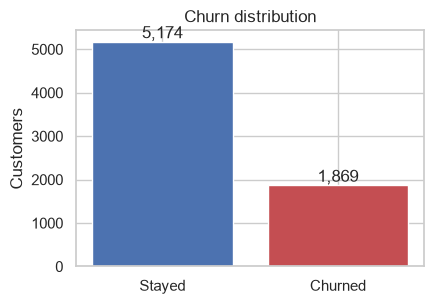

In [6]:
counts = df["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"})
print(counts, f"\nchurn rate = {df['Churn'].mean():.3f}")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set(title="Churn distribution", ylabel="Customers")
save(fig, "eda_churn_distribution.png")

About a quarter of customers churned. The classes are imbalanced, so a model that always says
"stays" would already be about 73% accurate. That is why accuracy alone is a poor yardstick here,
and why the project reports recall, precision, F1 and ROC-AUC next to a dummy baseline.

## 3. Tenure and charges

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.425,1679.525
1,10.0,79.650,703.550


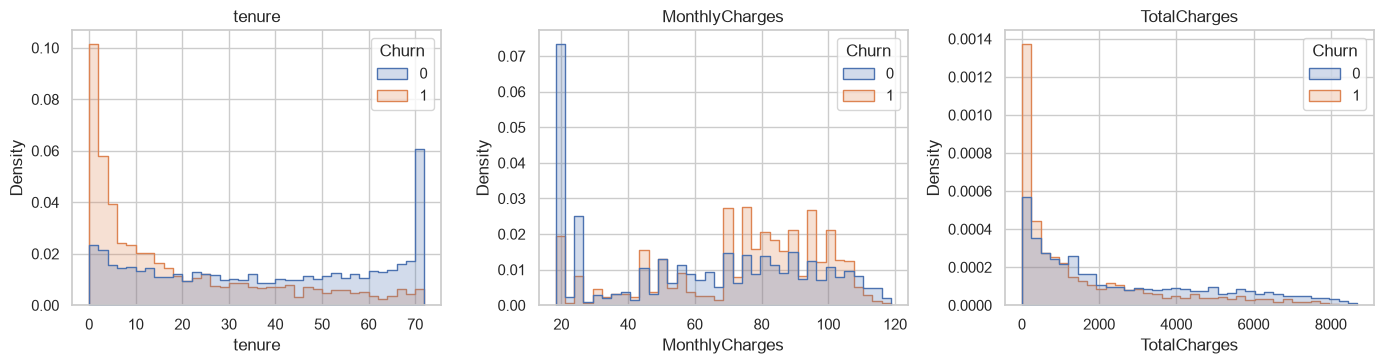

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", stat="density", common_norm=False,
                 bins=36, element="step", ax=ax)
    ax.set_title(col)
save(fig, "eda_numeric_distributions.png")
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median()

* **Tenure** is the clearest separator. Churners are concentrated in the first months (median
  10 vs 38 months for customers who stayed).
* **Monthly charges** are higher for churners (median about \$80 vs \$64), driven by the expensive
  fibre plans.
* **Total charges** are *lower* for churners, simply because they have been customers for less
  time. TotalCharges is strongly correlated with tenure (see below), so it adds little new
  information.
* Tenure stops at 72 months, with a visible pile-up there. The source appears to cap the values.

In [8]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


## 4. Contract, payment method and internet service

churn_rate  customers
Contract        Month-to-month                  0.427       3875
                One year                        0.113       1473
                Two year                        0.028       1695
PaymentMethod   Bank transfer (automatic)       0.167       1544
                Credit card (automatic)         0.152       1522
                Electronic check                0.453       2365
                Mailed check                    0.191       1612
InternetService DSL                             0.190       2421
                Fiber optic                     0.419       3096
                No                              0.074       1526

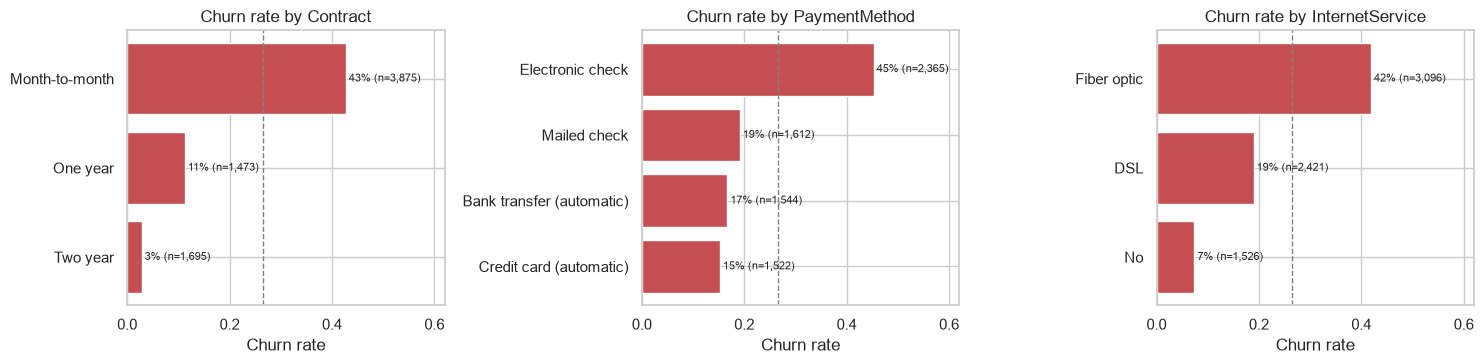

In [9]:
def churn_rate(col):
    return df.groupby(col, observed=True)["Churn"].agg(churn_rate="mean", customers="size")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["Contract", "PaymentMethod", "InternetService"]):
    r = churn_rate(col).sort_values("churn_rate")
    ax.barh(r.index, r["churn_rate"], color="#C44E52")
    ax.axvline(df["Churn"].mean(), ls="--", c="grey", lw=1)
    ax.set(title=f"Churn rate by {col}", xlabel="Churn rate")
    for i, (v, n) in enumerate(zip(r["churn_rate"], r["customers"])):
        ax.text(v, i, f" {v:.0%} (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 0.62)
save(fig, "eda_contract_payment_internet.png")
pd.concat({c: churn_rate(c) for c in ["Contract", "PaymentMethod", "InternetService"]}).round(3)

The dashed line is the overall churn rate.

* **Contract** shows the biggest gap: month-to-month customers churn far more than customers on
  one- or two-year contracts. Long contracts carry exit costs, so part of this gap is the
  contract itself rather than customer satisfaction.
* **Electronic check** payers churn at roughly 3× the rate of automatic payment methods.
* **Fibre optic** customers churn more than DSL customers, even though fibre is the premium product.
  The data cannot say whether that is price, service quality or competition.

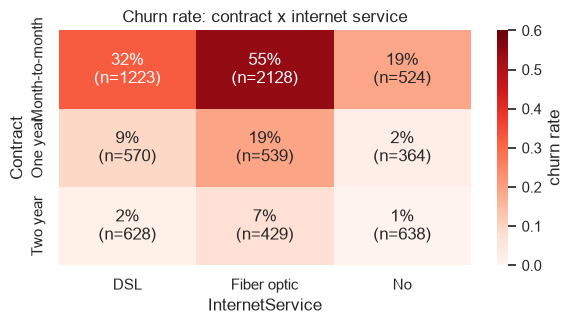

In [10]:
# These factors overlap. Churn rate by contract x internet service:
rate = pd.crosstab(df["Contract"], df["InternetService"], values=df["Churn"], aggfunc="mean")
n = pd.crosstab(df["Contract"], df["InternetService"])
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.heatmap(rate, annot=rate.map("{:.0%}".format) + "\n(n=" + n.astype(str) + ")",
            fmt="", cmap="Reds", vmin=0, vmax=0.6, cbar_kws={"label": "churn rate"}, ax=ax)
ax.set_title("Churn rate: contract x internet service")
save(fig, "eda_contract_internet_heatmap.png")

The fibre effect holds *within* every contract type, and the contract effect holds within every
internet type. Month-to-month fibre customers are the highest-churn segment in the data. This is
why the model needs both inputs rather than either alone.

## 5. Add-on services

All customers, 0 add-ons: 0.214


,churn_rate,customers
num_addon_services,,
0.0,0.522,693
1.0,0.458,966
2.0,0.358,1033
3.0,0.274,1118
4.0,0.223,852
5.0,0.124,571
6.0,0.053,284


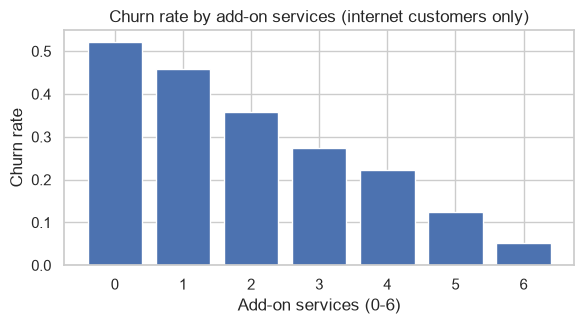

In [11]:
internet = df[df["InternetService"] != "No"]
addons = internet.groupby("num_addon_services")["Churn"].agg(churn_rate="mean", customers="size")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(addons.index.astype(int), addons["churn_rate"], color="#4C72B0")
ax.set(title="Churn rate by add-on services (internet customers only)",
       xlabel="Add-on services (0-6)", ylabel="Churn rate")
save(fig, "eda_addon_services.png")
print("All customers, 0 add-ons:", round(df.loc[df["num_addon_services"] == 0, "Churn"].mean(), 3))
addons.round(3)

Add-ons (online security, backup, device protection, tech support, streaming TV/movies) only exist
for internet customers, so the chart is restricted to them. Customers without internet always have
0 add-ons and churn rarely; mixing them in would make the 0 bar look misleadingly low.

Among internet customers, churn falls steadily as the number of add-ons rises. Customers with more
services may be more locked in, more satisfied, or both. The data cannot separate those
explanations.

In [12]:
pd.concat({c: churn_rate(c) for c in ["OnlineSecurity", "TechSupport"]}).round(3)

churn_rate  customers
               OnlineSecurity                            
OnlineSecurity No                        0.418       3498
               No internet service       0.074       1526
               Yes                       0.146       2019
TechSupport    No                        0.416       3473
               No internet service       0.074       1526
               Yes                       0.152       2044

## 6. Demographics

churn_rate  customers
gender        Female       0.269       3488
              Male         0.262       3555
SeniorCitizen No           0.236       5901
              Yes          0.417       1142
Partner       No           0.330       3641
              Yes          0.197       3402
Dependents    No           0.313       4933
              Yes          0.155       2110

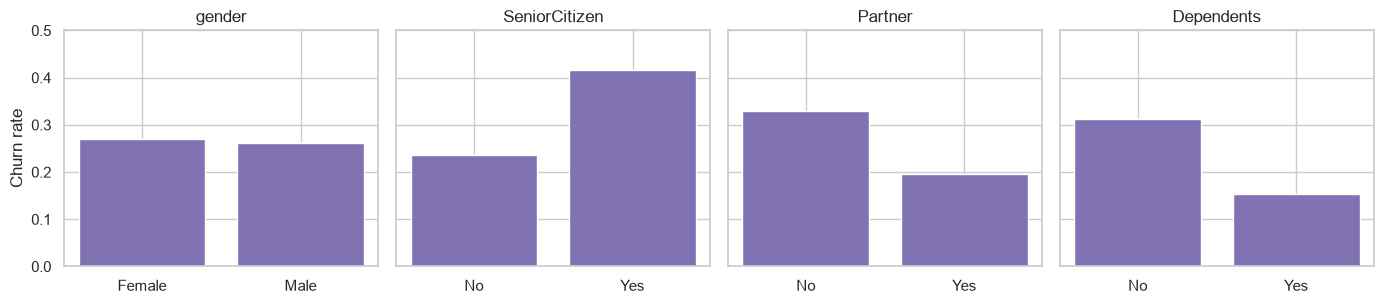

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    r = churn_rate(col)
    ax.bar(r.index, r["churn_rate"], color="#8172B3")
    ax.set(title=col, ylim=(0, 0.5))
axes[0].set_ylabel("Churn rate")
save(fig, "eda_demographics.png")
pd.concat({c: churn_rate(c) for c in ["gender", "SeniorCitizen", "Partner", "Dependents"]}).round(3)

* **Gender** makes essentially no difference.
* **Senior citizens** churn more. Customers **without a partner or dependents** churn more.
  These groups also differ in tenure and contract type, so part of this gap is likely explained by
  those factors. The model's permutation importance (below) gives these columns little weight once
  tenure and contract are known.

## 7. Model results (from `python -m src.train`)

The notebook does not retrain. It reads the metrics file written by the training script.

In [14]:
metrics = json.loads(config.METRICS_PATH.read_text(encoding="utf-8"))
rows = []
for name, m in metrics["test"].items():
    c = metrics["cv"][name]
    rows.append({"model": name, "cv_roc_auc": c["cv_roc_auc_mean"], "cv_std": c["cv_roc_auc_std"],
                 **{k: m[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
t = metrics["test_final_tuned"]
rows.append({"model": f"final @ {t['threshold']:.2f}",
             **{k: t[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
print(metrics["selection_reason"])
pd.DataFrame(rows).set_index("model").round(3)

Highest mean CV ROC-AUC was Random Forest (0.8479). Models within 0.005 of it: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']. Chose the most interpretable of these: Logistic Regression.


,cv_roc_auc,cv_std,accuracy,precision,recall,f1,roc_auc
model,,,,,,,
Dummy (prior),0.500,0.000,0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.846,0.012,0.799,0.653,0.519,0.578,0.842
Random Forest,0.848,0.010,0.803,0.675,0.495,0.571,0.844
HistGradientBoosting,0.848,0.011,0.806,0.695,0.481,0.569,0.845
final @ 0.14,NaN,NaN,0.663,0.436,0.925,0.593,0.842


In [15]:
perm = pd.DataFrame(metrics["explainability"]["permutation_importance"]).T.sort_values("mean", ascending=False)
perm.round(4).head(10)

,mean,std
tenure,0.2213,0.0034
Contract,0.0391,0.0044
TotalCharges,0.0342,0.0034
MonthlyCharges,0.0335,0.0055
InternetService,0.0335,0.0072
OnlineSecurity,0.0032,0.0011
StreamingMovies,0.0030,0.0018
TechSupport,0.0029,0.0010
StreamingTV,0.0028,0.0023
MultipleLines,0.0026,0.0016


## 8. Takeaways

1. Churn in this dataset is concentrated among **new, month-to-month customers**, especially those on
   **fibre optic** and paying by **electronic check**.
2. **Tenure** is by far the input the final model relies on most, followed by contract, charges and
   internet service. Demographics add little once those are known.
3. All three models reach a similar ROC-AUC (about 0.84–0.85). The more interpretable logistic
   regression was chosen, and its decision threshold was lowered to catch more churners at the
   cost of more false alarms.
4. All findings are associations in one fictional, single-snapshot dataset. Retention actions
   based on them should be tested (e.g. A/B tests) before rolling them out.